## Import Packages


In [1]:
# Import Required Packages
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

## Load Dataset


In [2]:
# Loading and examining the dataset
penguins_df = pd.read_csv("/content/penguins.csv")
penguins_df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
penguins_df.shape

(344, 5)

In [5]:
penguins_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    object 
dtypes: float64(4), object(1)
memory usage: 13.6+ KB


## Dealing with null values and outliers


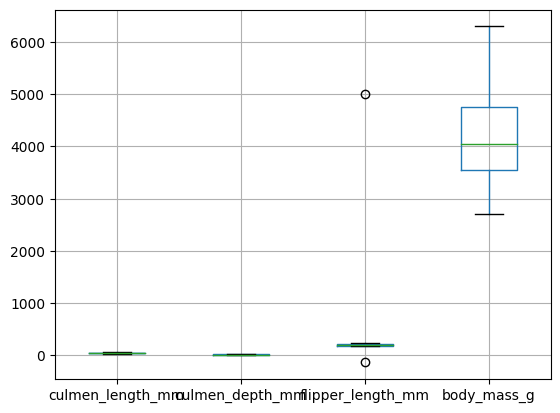

In [6]:
penguins_df.boxplot()
plt.show()

In [9]:
penguins_df[penguins_df["flipper_length_mm"] > 4000]

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
9,42.0,20.2,5000.0,4250.0,MALE


In [10]:
penguins_df[penguins_df["flipper_length_mm"] < 0]

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
14,34.6,21.1,-132.0,4400.0,MALE


In [12]:
penguins_df = penguins_df.dropna()
penguins_clean = penguins_df.drop([9, 14])
penguins_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 333 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   333 non-null    float64
 1   culmen_depth_mm    333 non-null    float64
 2   flipper_length_mm  333 non-null    float64
 3   body_mass_g        333 non-null    float64
 4   sex                333 non-null    object 
dtypes: float64(4), object(1)
memory usage: 15.6+ KB


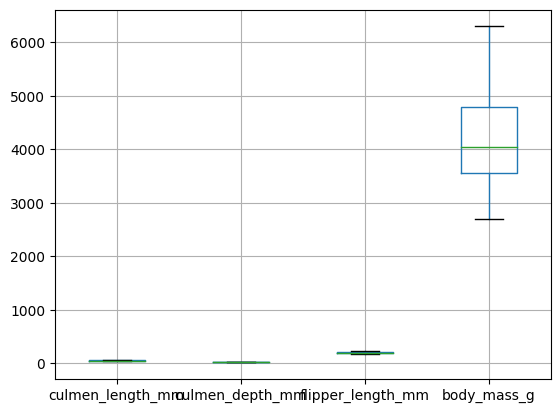

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [13]:
penguins_clean.boxplot()
plt.show()
penguins_clean.head()

## Perform preprocessing steps on the dataset


In [19]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
penguins_clean['sex'] = le.fit_transform(penguins_clean['sex'])
penguins_clean.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,2
1,39.5,17.4,186.0,3800.0,1
2,40.3,18.0,195.0,3250.0,1
4,36.7,19.3,193.0,3450.0,1
5,39.3,20.6,190.0,3650.0,2


In [27]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
penguins_clean[penguins_clean.columns] = scaler.fit_transform(penguins_clean[penguins_clean.columns])
penguins_clean.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,0.254545,0.666667,0.152542,0.291667,1.0
1,0.269091,0.511905,0.237288,0.305556,0.5
2,0.298182,0.583333,0.389831,0.152778,0.5
4,0.167273,0.738095,0.355932,0.208333,0.5
5,0.261818,0.892857,0.305085,0.263889,1.0


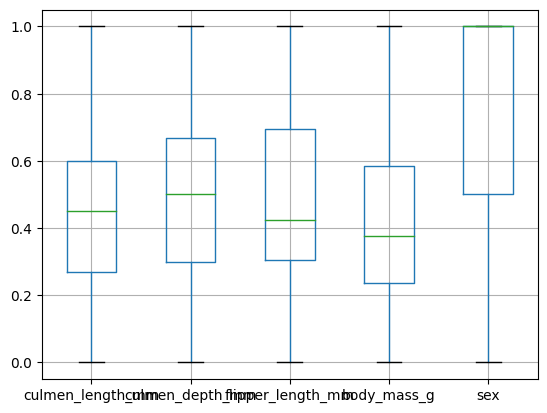

In [28]:
penguins_clean.boxplot()
plt.show()

## Detect the optimal number of clusters for k-means clustering


In [29]:
from sklearn.cluster import KMeans

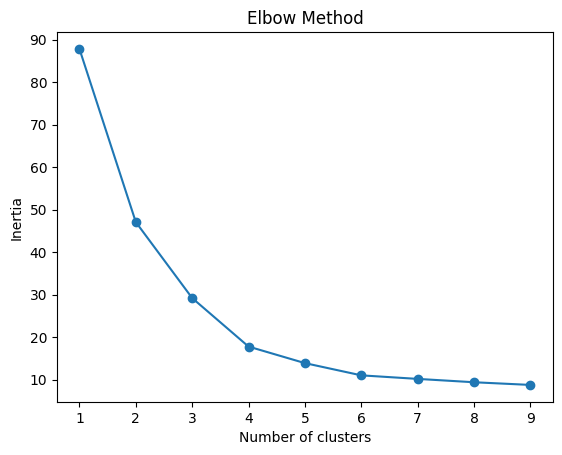

In [30]:
inertia = [] #Sum of squared distances of samples to their closest cluster center
for k in range(1, 10):
    kmeans = KMeans(n_clusters=k, random_state=42).fit(penguins_clean)
    inertia.append(kmeans.inertia_)
plt.plot(range(1, 10), inertia, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

## Run the k-means clustering algorithm


In [41]:
n_clusters = 4
kmeans = KMeans(n_clusters=n_clusters, random_state=42).fit(penguins_clean)

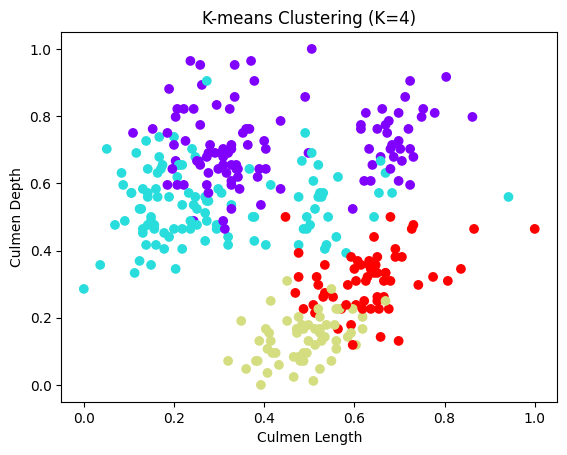

In [59]:
plt.scatter(penguins_clean['culmen_length_mm'], penguins_clean['culmen_depth_mm'], c=kmeans.labels_, cmap="rainbow")
plt.xlabel("Culmen Length")
plt.ylabel("Culmen Depth")
plt.title(f"K-means Clustering (K={n_clusters})")
plt.show()

## Run the Agglomerative Clustering algorithm

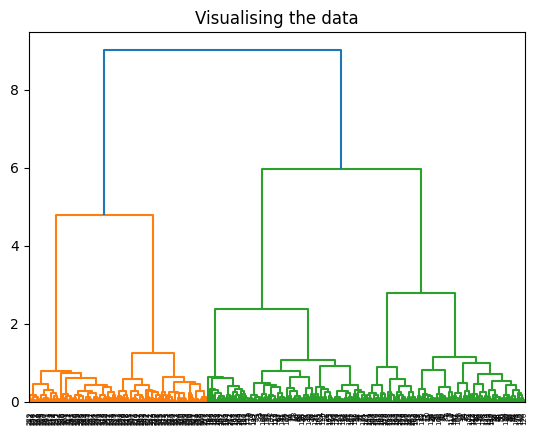

In [44]:
import scipy.cluster.hierarchy as shc
plt.title('Visualising the data')
Dendrogram = shc.dendrogram((shc.linkage(penguins_clean, method ='ward')))

In [45]:
from sklearn.cluster import AgglomerativeClustering
agglo=AgglomerativeClustering(n_clusters = 4).fit(penguins_clean)

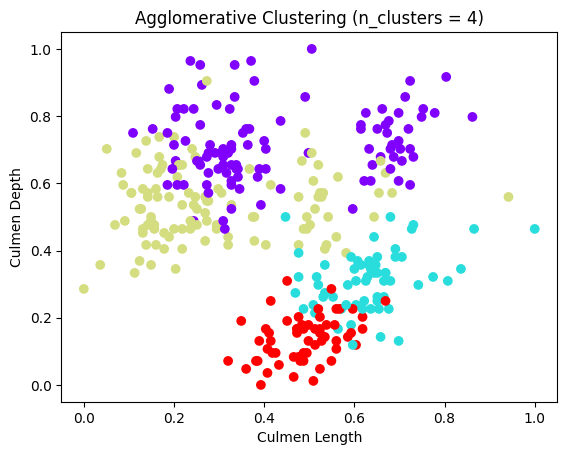

In [58]:
plt.scatter(penguins_clean['culmen_length_mm'], penguins_clean['culmen_depth_mm'],
           c = agglo.labels_, cmap ='rainbow')
plt.xlabel("Culmen Length")
plt.ylabel("Culmen Depth")
plt.title(f"Agglomerative Clustering (n_clusters = 4)")
plt.show()

## Run the DBSCAN clustering algorithm

In [49]:
from sklearn.cluster import DBSCAN

In [50]:
db = DBSCAN(eps=0.3, min_samples=10).fit(penguins_clean)

In [54]:
db.labels_

array([ 0,  1,  1,  1,  0,  1,  0,  1,  0,  1,  1,  0,  1,  0,  1,  0,  1,
        0,  0,  1,  0,  1,  1,  0,  1,  0,  1,  0,  1,  0,  0,  1,  1,  0,
        1,  0,  1,  0,  1,  0,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,
        1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,
        0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  0,  1,  0,  1,  1,  0,
        1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,
        0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,
        1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,
        0,  1,  0,  0,  1,  1,  0,  1,  0,  1,  0,  0,  1,  0,  1,  1,  0,
        1,  0,  1,  0,  1,  0,  1,  0,  0, -1,  1,  0,  1,  0,  1,  0,  1,
        0,  1,  0,  1,  0,  1,  0,  1,  0,  0,  1,  1,  0,  1,  0,  0,  1,
        0,  1,  1,  0,  1,  0,  0,  1,  1,  0,  1,  0,  1,  0,  1,  0,  0,
        1,  0,  1,  1,  0,  1,  0,  0,  1,  2,  3,  2,  3,  3,  2,  2,  3,
        2,  3,  2,  3,  2

In [52]:
# Number of clusters in labels, ignoring noise if present.
db_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)  #label=-1 for noise
db_noise = list(db.labels_).count(-1)

print("Estimated number of clusters: %d" % db_clusters)
print("Estimated number of noise points: %d" % db_noise)

Estimated number of clusters: 4
Estimated number of noise points: 2


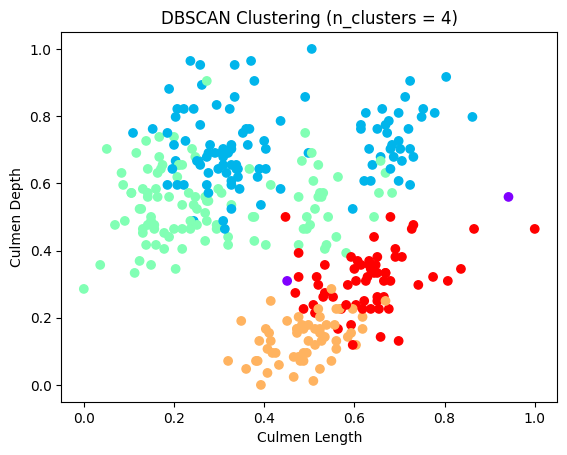

In [57]:
plt.scatter(penguins_clean['culmen_length_mm'], penguins_clean['culmen_depth_mm'],
           c = db.labels_, cmap ='rainbow')
plt.xlabel("Culmen Length")
plt.ylabel("Culmen Depth")
plt.title(f"DBSCAN Clustering (n_clusters = {db_clusters})")
plt.show()